# Phase 11.1: Softmax regression

**Owner:** Rafat · **Model:** `LogisticRegression` · **Writes to:** `data/processed/11_1_softmax/`

**What it means:** Softmax regression draws straight boundaries between the classes in the 60-number PCA space, then turns each square's 5 scores into 5 probabilities that add up to 1.

**Key idea:** It is the simplest model, so it is the reference: if SVM or MLP can't beat it, their extra complexity isn't worth it (hypothesis H1).

Full step-by-step guide and the results sheet: [team plan](https://claude.ai/artifact/Rst8GHxAbeHavg4JS2RZV3) (tab 11.1).

### What we agreed on (same for all three notebooks)
- Train on the **46,408 balanced training squares**, score on the **36,000 validation squares**. The test set is not loaded.
- Pipeline: `StandardScaler` → `PCA(60, random_state=42)` → model.
- Tuning: `GridSearchCV` on train only, `GroupKFold(5)` grouped by photo, `scoring="f1_macro"`.
- Main metric: validation **macro F1** (floor to beat: **0.187**, always answering "none"). Second: **pothole (D40) recall**.

### What to tune

| Setting | Values to try | What it controls |
|---|---|---|
| `C` | 0.01, 0.1, 1, 10 | How freely the model fits. Smaller C gives simpler, safer boundaries. |

**Fixed:** `class_weight="balanced"`, `max_iter=2000`, `random_state=SEED`.

## 1. Setup

Everything shared lives in `ml/training.py`, so this notebook only adds the model:
- `load_data()`: the agreed rows (46,408 balanced training squares, 36,000 validation squares);
- `make_pipeline(clf)`: `StandardScaler` → `PCA(60)` → your model;
- `CV`: `GroupKFold(5)`, folds split by photo;
- `search_table(gs, OUT)`: saves the grid search to `cv_results.csv` and returns the best row;
- `report(...)`: the same evaluation for every model; writes `results.json` and `confusion_matrix.png`.

Don't change `ml/training.py` on your own: a change there changes all three results.

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score
from sklearn.model_selection import GridSearchCV

sys.path.insert(0, str(Path.cwd().parents[1]))
from ml import config
from ml.training import CV, load_data, make_pipeline, output_dir, report, search_table

SEED = config.SEED
OUT = output_dir("11_1_softmax")     # this notebook writes only here

data = load_data()                # balanced train + validation; the test set is never loaded
X_tr, y_tr, groups_tr, X_va, y_va = data
print("train", X_tr.shape, "| val", X_va.shape)

train (46408, 1769) | val (36000, 1769)


## 2. Baseline: is it working at all? (Phase 10)

Fit the model once with default settings and score it on validation.

**Check:** clearly above 0.187.

In [2]:
from sklearn.linear_model import LogisticRegression

t0 = time.time()
base = make_pipeline(LogisticRegression(class_weight="balanced", max_iter=2000, random_state=SEED))
base.fit(X_tr, y_tr)
base_f1 = f1_score(y_va, base.predict(X_va), average="macro")
print(f"baseline val macro F1 {base_f1:.4f} | floor 0.187 | {time.time() - t0:.1f}s")

baseline val macro F1 0.2093 | floor 0.187 | 9.8s


## 3. Grid search, on train only

Try every combination in the table above with `GridSearchCV(..., cv=CV, scoring="f1_macro", n_jobs=-1, return_train_score=True)` and `groups=groups_tr`.

**Check:** one row per combination in `gs.cv_results_`; note how long it took.

In [3]:
pipe = make_pipeline(LogisticRegression(class_weight="balanced", max_iter=2000, random_state=SEED))
grid = {"clf__C": [0.01, 0.1, 1, 10]}

gs = GridSearchCV(pipe, grid, cv=CV, scoring="f1_macro", n_jobs=-1, return_train_score=True)
t0 = time.time()
gs.fit(X_tr, y_tr, groups=groups_tr)
print(f"{len(gs.cv_results_['params'])} settings x 5 folds in {time.time() - t0:.0f}s")
print("best:", gs.best_params_, "| CV macro F1", round(gs.best_score_, 4))

4 settings x 5 folds in 83s
best: {'clf__C': 10} | CV macro F1 0.287


## 4. Read the search

`cv, best = search_table(gs, OUT)` saves the search and returns the best row. Plot the mean macro F1 per setting.

**Check:** if the best value is at the edge of the grid, add one value beyond it once and note it.

,C,mean_train_score,mean_test_score,std_test_score,mean_fit_time
0,0.01,0.2937,0.2869,0.0061,36.0971
1,0.10,0.2937,0.2869,0.0061,37.5953
2,1.00,0.2937,0.2869,0.0061,29.7816
3,10.00,0.2937,0.2870,0.0061,23.4444


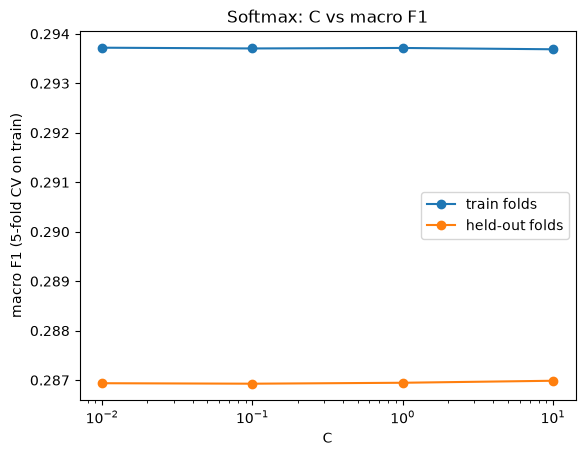

edge check C=100: CV macro F1 0.2870 ± 0.0061 (best in grid 0.2870)


In [4]:
cv, best = search_table(gs, OUT)          # saves cv_results.csv, returns the best row
cv["C"] = cv["param_clf__C"].astype(float)
display(cv[["C", "mean_train_score", "mean_test_score", "std_test_score", "mean_fit_time"]].round(4))

ax = cv.plot(x="C", y=["mean_train_score", "mean_test_score"], logx=True, marker="o")
ax.legend(["train folds", "held-out folds"])
ax.set(ylabel="macro F1 (5-fold CV on train)", title="Softmax: C vs macro F1")
plt.show()

# Edge check: best C at the end of the grid -> try one value beyond it once and log it
best_C = best["params"]["clf__C"]
edge = None
if best_C in (0.01, 10):
    from sklearn.model_selection import cross_val_score
    extra_C = 100 if best_C == 10 else 0.001
    s = cross_val_score(make_pipeline(LogisticRegression(C=extra_C, class_weight="balanced",
                        max_iter=2000, random_state=SEED)), X_tr, y_tr, groups=groups_tr,
                        cv=CV, scoring="f1_macro", n_jobs=-1)
    edge = {"try": f"edge check C={extra_C}", "C": extra_C, "cv_macro_f1": round(s.mean(), 4)}
    print(f"edge check C={extra_C}: CV macro F1 {s.mean():.4f} ± {s.std():.4f} "
          f"(best in grid {best['mean_test_score']:.4f})")
else:
    print(f"best C = {best_C} is inside the grid: no edge check needed")

## 5. Final model, scored on validation

`report(pipe, data, OUT, "11.1 Softmax", best, train_seconds)` writes `results.json` and `confusion_matrix.png`.

**Check:** read the D40 row of the confusion matrix: where do the missed potholes go?

                          precision    recall  f1-score   support

D00 · Longitudinal crack      0.033     0.163     0.055       743
  D10 · Transverse crack      0.027     0.396     0.051       323
   D20 · Alligator crack      0.171     0.249     0.203      2915
           D40 · Pothole      0.033     0.508     0.061       413
        none · No damage      0.969     0.520     0.677     31606

                accuracy                          0.489     36000
               macro avg      0.247     0.367     0.209     36000
            weighted avg      0.866     0.489     0.613     36000

val macro F1 0.2094 | train macro F1 0.2924 | floor 0.187


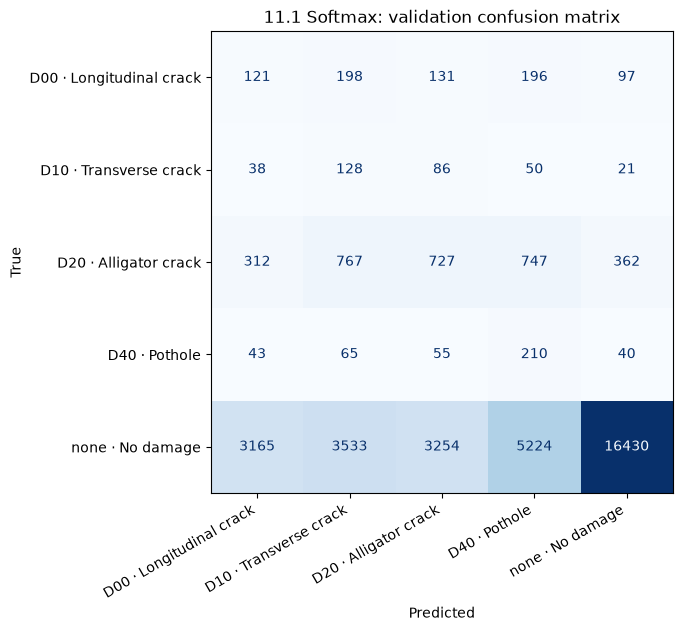

In [5]:
res = report(gs.best_estimator_, data, OUT, "11.1 Softmax", best, gs.refit_time_)

## 6. Check the train vs validation gap

Compare train and validation macro F1. Both low and close means underfitting: expected for the simplest model.

In [6]:
gap = res["train_macro_f1"] - res["val_macro_f1"]
print(f"train {res['train_macro_f1']} | val {res['val_macro_f1']} | gap {gap:.3f}")
print(f"CV {res['cv_macro_f1_mean']} ± {res['cv_macro_f1_std']} | D40 recall {res['per_class']['D40']['recall']}")
if gap > 0.15:
    print("-> overfitting: try a smaller C")
elif res["val_macro_f1"] < 0.5:
    print("-> both low and close: underfitting, as expected for a straight-line model")
else:
    print("-> fits reasonably; no big gap")

train 0.2924 | val 0.2094 | gap 0.083
CV 0.287 ± 0.0061 | D40 recall 0.5085
-> both low and close: underfitting, as expected for a straight-line model


## 7. Diagnose before changing anything (Phase 12)

Train − validation gap above 0.15: overfitting. Both low and close: underfitting. Change **one** thing at a time, keep it only if validation macro F1 goes up, and log every try (also the failed ones).

In [7]:
# Extra experiment (logged separately, not the main result): feature test for hypothesis H2
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

log = [{"try": "agreed run", "C": best_C, "val_macro_f1": res["val_macro_f1"]}]
if edge:
    log.append(edge)
hog_cols, simple_cols = slice(0, 1764), slice(1764, 1769)
for name, cols, use_pca in [("HOG only", hog_cols, True), ("5 measures only", simple_cols, False), ("both", slice(None), True)]:
    steps = [("scale", StandardScaler())]
    if use_pca:   # PCA(60) is impossible on 5 columns
        steps.append(("pca", PCA(n_components=60, random_state=SEED)))
    steps.append(("clf", LogisticRegression(C=best_C, class_weight="balanced", max_iter=2000, random_state=SEED)))
    m = Pipeline(steps).fit(X_tr[:, cols], y_tr)
    f = f1_score(y_va, m.predict(X_va[:, cols]), average="macro")
    log.append({"try": f"H2: {name}", "C": best_C, "val_macro_f1": round(f, 4)})
    print(f"{name:16s} val macro F1 {f:.4f}")

pd.DataFrame(log).to_csv(OUT / "experiments_log.csv", index=False)
pd.DataFrame(log)

HOG only         val macro F1 0.2078


5 measures only  val macro F1 0.2313


both             val macro F1 0.2094


,try,C,val_macro_f1,cv_macro_f1
0,agreed run,10,0.2094,NaN
1,edge check C=100,100,NaN,0.287
2,H2: HOG only,10,0.2078,NaN
3,H2: 5 measures only,10,0.2313,NaN
4,H2: both,10,0.2094,NaN


## 8. Save and hand in

`joblib.dump(...)` the final pipeline to `OUT / "best_pipeline.joblib"`. Then import `results.json` in the Results sheet tab of the team plan, add your observations and download the PDF.

In [8]:
import joblib

joblib.dump(gs.best_estimator_, OUT / "best_pipeline.joblib")
print("saved:", sorted(p.name for p in OUT.iterdir()))

saved: ['best_pipeline.joblib', 'confusion_matrix.png', 'cv_results.csv', 'experiments_log.csv', 'results.json']
